# MissForest feature and exact rule audit

**A01.2 · Sprint 6 · Subteam A · Rishank Goyal**

This paired review separates the gas-feature ablation from the effect of exact geometry rules. The decay correction changed anchor mean skill by about −0.001. Exact rules recovered many geometry gaps, while the forest made larger errors on the remaining altitude gaps.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Matched comparisons

Both comparisons use the 30% MCAR anchor with ±5% measured noise. The gas ablation holds the model-only arm fixed and toggles decay correction while retaining the spatial feature. The rules comparison holds the feature setting fixed. Rules first applies the synthetic identity altitude = x + y + 100 when the required inputs are valid, including its unique inverses for x and y. At this noise level, the gas sum and overgrowth identities are disabled for exact filling.

The rules-first pipeline fits the forest on rule-prepared training data. For the residual analysis, we compare errors on the same test gaps that the rule leaves for the forest.

In [1]:
%matplotlib inline
from io import StringIO
from math import isclose
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
# Archived score extract. Rows and columns are restricted to this analysis.
macro_evidence = pd.read_csv(StringIO("""
generator_seed,split_seed,arm,domain_features,macro_skill
219,617,model,False,0.6642341630541152
219,631,model,False,0.6608413113918605
219,653,model,False,0.6762915704986026
220,617,model,False,0.648656961862767
220,631,model,False,0.6492004161908569
220,653,model,False,0.6442835041295262
221,617,model,False,0.663351161771389
221,631,model,False,0.657066562078171
221,653,model,False,0.6468787822696609
219,617,model,True,0.6596825490762511
219,631,model,True,0.6571734366552107
219,653,model,True,0.6757834428651043
220,617,model,True,0.6447390835743599
220,631,model,True,0.6479006784508734
220,653,model,True,0.6469302627325839
221,617,model,True,0.6634616074595393
221,631,model,True,0.654266810658674
221,653,model,True,0.6521064775801411
219,617,rules,False,0.6582516767134371
219,631,rules,False,0.6643964536132834
219,653,rules,False,0.6902337421604657
220,617,rules,False,0.6671955985809694
220,631,rules,False,0.6390887356977939
220,653,rules,False,0.6456980079626903
221,617,rules,False,0.6482789447032163
221,631,rules,False,0.6436746825913235
221,653,rules,False,0.6542374392864106
219,617,rules,True,0.6574661465786835
219,631,rules,True,0.6616410912938983
219,653,rules,True,0.687558698559858
220,617,rules,True,0.6647607749363135
220,631,rules,True,0.6398668071742381
220,653,rules,True,0.6487402887119809
221,617,rules,True,0.6502701500389256
221,631,rules,True,0.6443711715808755
221,653,rules,True,0.6529169131933055
"""))

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
rule_evidence = pd.read_csv(StringIO("""
generator_seed,split_seed,attribute,hidden_n,direct_n,remaining_n,direct_rules_mae,remaining_model_mae,remaining_rules_mae,direct_skill_delta,remaining_skill_delta
219,617,x,616,296,320,0,3.083088639590474,3.457129963949373,0.0543762797956848,-0.007905761148933099
219,617,y,606,296,310,0,19.56270126948362,24.10367000980952,0.1076714044735366,-0.0797609105049026
219,617,install_date,584,0,584,,40.56736667299002,26.32094696486234,0,0.0413019648906953
219,617,altitude,597,279,318,0,18.8901704829867,32.2026987167598,0.0733743632604338,-0.2026124235828393
219,617,measured_humid,618,0,618,,0.0718844047525401,0.0719876760119747,0,-0.0005930660015899
219,617,measured_salt,575,0,575,,0.139510710400903,0.1394215014075412,0,0.0004125601142332
219,617,measured_overgrowth,616,0,616,,0.09647228554927829,0.0945599568387285,0,0.0064329653333524
219,617,life,585,0,585,,90.70276005747355,87.25634335707605,0,0.0125537273163097
219,617,measured_gas_a,578,0,578,,198.4332304805347,223.5957711382202,0,-0.0206200491129691
219,617,measured_gas_b,624,0,624,,214.3855757913603,221.7031149264453,0,-0.0069074184262795
219,617,measured_gas_c,627,0,627,,193.2302609013663,201.9545438213086,0,-0.0088955768878985
219,617,total_gas,589,0,589,,254.6399616435117,256.855547189765,0,-0.0019161973215412
219,617,leakage,609,0,609,,0.0879515833896141,0.08752416169281869,0,0.00427490533433
219,631,x,570,266,304,0,1.903180595620859,2.497159193417834,0.0494024215855259,-0.0122395101830326
219,631,y,587,296,291,0,21.10535651750037,24.92944592031857,0.1301480384415391,-0.0736716329837865
219,631,install_date,591,0,591,,31.60770632289029,18.72628473939021,0,0.0379870123066065
219,631,altitude,638,316,322,0,20.49120255268228,32.43942625050889,0.07801522375400299,-0.1692025697378912
219,631,measured_humid,605,0,605,,0.0754007817307159,0.0737903503019648,0,0.009381991579650801
219,631,measured_salt,593,0,593,,0.1269869896988256,0.1275802780935331,0,-0.0027567954048186
219,631,measured_overgrowth,554,0,554,,0.09806453380996211,0.0975132075950299,0,0.0018807848597778
219,631,life,582,0,582,,95.33864359699704,93.230434457616,0,0.0075329484822195
219,631,measured_gas_a,594,0,594,,221.2659484000851,214.9308021356115,0,0.0051073890924099
219,631,measured_gas_b,596,0,596,,217.5354964199993,230.4694073090798,0,-0.0118669373036407
219,631,measured_gas_c,627,0,627,,171.4823623191263,176.9040679870679,0,-0.0054763842193718
219,631,total_gas,587,0,587,,242.6462739961031,232.5403878476729,0,0.009164885455377299
219,631,leakage,572,0,572,,0.08878669439022641,0.08832274397648771,0,0.0046726445783685
219,653,x,603,287,316,0,2.406399611837262,2.880073150795216,0.0487966716208806,-0.0100154458555177
219,653,y,577,280,297,0,13.97166089392746,16.13953009458583,0.1293284294196872,-0.0525168966228004
219,653,install_date,599,0,599,,34.31742375950533,21.00334626708341,0,0.037610122345044
219,653,altitude,593,277,316,0,14.65389177572592,22.39162015093116,0.1128856148738163,-0.1396733786453132
219,653,measured_humid,617,0,617,,0.06900462533092511,0.0690927005800495,0,-0.0004819979626769
219,653,measured_salt,585,0,585,,0.1227582851950553,0.1207878601713599,0,0.0094278575454696
219,653,measured_overgrowth,564,0,564,,0.08731023296785589,0.0877470202026749,0,-0.0013383768993307
219,653,life,567,0,567,,92.4153888057257,92.20170294330768,0,0.0007410640671096
219,653,measured_gas_a,592,0,592,,189.4117666954088,206.8076017049703,0,-0.0143883507796928
219,653,measured_gas_b,615,0,615,,191.6943752247785,193.7695786967053,0,-0.0019550676477087
219,653,measured_gas_c,630,0,630,,180.6111373112166,169.6422397753505,0,0.0110206591273164
219,653,total_gas,606,0,606,,252.8198806377704,239.9069536247331,0,0.011705161419888
219,653,leakage,612,0,612,,0.08858137067292809,0.0873693553139399,0,0.0119322580256276
220,617,x,584,310,274,0,3.204169014604315,3.361923483315903,0.0783153346313297,-0.0029785504704365
220,617,y,586,286,300,0,20.88258567443554,24.36640395413561,0.1390879330992692,-0.0610018959849425
220,617,install_date,599,0,599,,47.86953856356736,27.35983166577807,0,0.0609224389763496
220,617,altitude,609,300,309,0,19.90235892164814,29.46274465551702,0.0781401831114428,-0.1393405590191729
220,617,measured_humid,578,0,578,,0.0758880090849378,0.0741716625413168,0,0.0095224593132416
220,617,measured_salt,584,0,584,,0.146156408228597,0.1487495890997758,0,-0.0125162048755892
220,617,measured_overgrowth,629,0,629,,0.09201617715323469,0.0906837420710204,0,0.0044478129746123
220,617,life,595,0,595,,94.7047332420895,92.6635947819168,0,0.0074970959224414
220,617,measured_gas_a,569,0,569,,193.7020426610713,178.8173525583836,0,0.01213042480461
220,617,measured_gas_b,595,0,595,,210.09893784568,176.5686069119326,0,0.0314302961664827
220,617,measured_gas_c,605,0,605,,174.5315611702816,154.4032993537867,0,0.0212964795725176
220,617,total_gas,594,0,594,,276.0790630378805,239.6240065236547,0,0.0341176584018568
220,617,leakage,600,0,600,,0.0895476828634984,0.0896274986705821,0,-0.000788918918617
220,631,x,594,288,306,0,2.713075144585318,3.585420465282335,0.0553093976928666,-0.0181738608478545
220,631,y,599,310,289,0,21.73166968585346,27.9081367345015,0.1337034610608297,-0.115042470808152
220,631,install_date,600,0,600,,37.90403513533909,21.38425454635081,0,0.0486536539977958
220,631,altitude,606,298,308,0,23.02035890878596,41.31145133639021,0.0967431780604138,-0.2785491454982503
220,631,measured_humid,599,0,599,,0.07461983012445041,0.07445857250858701,0,0.0009604114625841
220,631,measured_salt,620,0,620,,0.1263935591204781,0.1309415310222225,0,-0.0219091577093487
220,631,measured_overgrowth,580,0,580,,0.0958875377138135,0.0948617980856912,0,0.0035131129219118
220,631,life,618,0,618,,92.97090191001068,90.04366447795825,0,0.0102795739411718
220,631,measured_gas_a,595,0,595,,176.2143481902847,199.005648720254,0,-0.0187010767328967
220,631,measured_gas_b,632,0,632,,186.6830298586071,199.1743724893603,0,-0.0118445019430143
220,631,measured_gas_c,591,0,591,,166.5063864135299,169.306677730603,0,-0.0030366845913507
220,631,total_gas,583,0,583,,254.4185377215737,255.2879715770753,0,-0.0008493503174105
220,631,leakage,612,0,612,,0.08756147794513899,0.08616463166974229,0,0.0145031327144433
220,653,x,569,270,299,0,2.97026284796831,3.237547142572077,0.0579063192679905,-0.0055734712383378
220,653,y,626,319,307,0,15.18042740140295,21.12162710383145,0.1432034107976824,-0.1374697247999358
220,653,install_date,573,0,573,,41.93677589742045,27.32980063062399,0,0.0423883762268586
220,653,altitude,600,288,312,0,16.23025352393902,29.117633362571,0.1167686832899966,-0.2272444054285734
220,653,measured_humid,584,0,584,,0.07835423711702159,0.0791133575902061,0,-0.0043909314033697
220,653,measured_salt,608,0,608,,0.1497683177045282,0.1527196313212331,0,-0.0137760189369104
220,653,measured_overgrowth,581,0,581,,0.101232705054425,0.1018189062224889,0,-0.0019285458936483
220,653,life,581,0,581,,104.1594493274044,101.2390440331238,0,0.0104857954016923
220,653,measured_gas_a,573,0,573,,192.1427044437931,182.9584993173593,0,0.0072645652182044
220,653,measured_gas_b,619,0,619,,184.1577249060518,178.4997791005734,0,0.0053494903874138
220,653,measured_gas_c,607,0,607,,162.5819251284633,158.3217392331033,0,0.0045764907788513
220,653,total_gas,622,0,622,,242.6409287287455,237.6412189974986,0,0.0046823148137146
220,653,leakage,550,0,550,,0.0893445025495551,0.087142207846753,0,0.0212879892505332
221,617,x,600,292,308,0,2.870406474102546,3.766863313683601,0.0569652990154496,-0.0184084743376868
221,617,y,583,278,305,0,19.71472522790238,27.0095611434346,0.09156549346168261,-0.1344690531994035
221,617,install_date,603,0,603,,37.32487059977595,28.9137424469611,0,0.0250144766750051
221,617,altitude,617,309,308,0,20.53477712707082,44.18690203806774,0.09142087070207899,-0.3358004274263414
221,617,measured_humid,610,0,610,,0.07194791346378859,0.07190057367939,0,0.000276256164832
221,617,measured_salt,597,0,597,,0.1274676965986425,0.1279366998096012,0,-0.0022840327343217
221,617,measured_overgrowth,618,0,618,,0.0931642220450712,0.0947845798111904,0,-0.0054228089927749
221,617,life,591,0,591,,83.87453347519764,83.35325543104949,0,0.0018131998374552
221,617,measured_gas_a,620,0,620,,209.8607331984527,186.3117137337876,0,0.0184970983994557
221,617,measured_gas_b,614,0,614,,204.9310730213661,195.5802391258308,0,0.0085585427633605
221,617,measured_gas_c,574,0,574,,182.9753856756472,170.9943135550046,0,0.0126059897935752
221,617,total_gas,580,0,580,,258.6416036731848,252.6686080383334,0,0.0056101948241817
221,617,leakage,642,0,642,,0.0864676162961009,0.08523002951871279,0,0.0125684285854733
221,631,x,570,288,282,0,2.553358535269514,3.080823434942219,0.0621389206872487,-0.0107134184462476
221,631,y,632,329,303,0,20.75807828124402,29.85312442622923,0.146046728628405,-0.170489914744526
221,631,install_date,637,0,637,,35.08892774365601,20.34686247796561,0,0.0429300715642247
221,631,altitude,613,300,313,0,21.07118893852502,44.36776898244051,0.0898531441768546,-0.3503497599454931
221,631,measured_humid,589,0,589,,0.06780600408707591,0.06757252334355179,0,0.001337342820337
221,631,measured_salt,608,0,608,,0.1340556574191197,0.1353715679053781,0,-0.006618897552545
221,631,measured_overgrowth,598,0,598,,0.0928267699769173,0.0893996692018454,0,0.0121054755280255
221,631,life,579,0,579,,96.76709444222068,92.03951136955511,0,0.0165411691220561
221,631,measured_gas_a,590,0,590,,198.1114553615871,180.7736302928562,0,0.013613606041425
221,631,measured_gas_b,600,0,600,,196.1672981785284,181.7402061629678,0,0.013546153456298
221,631,measured_gas_c,592,0,592,,176.2055025346098,172.7479181487295,0,0.0037188602203944
221,631,total_gas,597,0,597,,248.1901356944955,245.7494908464151,0,0.0021490265925888
221,631,leakage,601,0,601,,0.0841278172747066,0.0835847696377531,0,0.0055481838395758
221,653,x,584,287,297,0,2.795243857472391,2.998042325636446,0.0594000108265284,-0.0042762616290184
221,653,y,619,320,299,0,15.43950086742534,21.42650055648731,0.1478854692186804,-0.1368901817717771
221,653,install_date,617,0,617,,36.70893246263707,24.2304070552706,0,0.0358803909775101
221,653,altitude,585,278,307,0,16.82794420777458,28.54134677285059,0.105062883344089,-0.2164318138717023
221,653,measured_humid,599,0,599,,0.0738532525664758,0.0725818695537111,0,0.0075290902847944
221,653,measured_salt,590,0,590,,0.1461759920293118,0.1465578797089645,0,-0.0017764338928957
221,653,measured_overgrowth,586,0,586,,0.1050176327679048,0.1017168383131278,0,0.0106122108226864
221,653,life,598,0,598,,92.19685964275668,90.21683068062477,0,0.0062020177942004
221,653,measured_gas_a,570,0,570,,182.4226999895599,190.9556387610673,0,-0.006804354944517
221,653,measured_gas_b,559,0,559,,179.9641469398614,193.6817598127767,0,-0.012851391758102
221,653,measured_gas_c,591,0,591,,193.083292760998,201.485221054728,0,-0.0087477100572228
221,653,total_gas,602,0,602,,245.0361222938442,239.1749030533139,0,0.0056079496650478
221,653,leakage,587,0,587,,0.0873957287789819,0.0854153644357017,0,0.0201337879628357
"""))

In [4]:
# Archived score extract. Rows and columns are restricted to this analysis.
altitude_scores = pd.read_csv(StringIO("""
generator_seed,split_seed,arm,skill,tolerance
219,617,model,0.6391232813461627,0.371859296482412
219,617,rules,0.5098852210237573,0.5125628140703518
219,631,model,0.6318023845684664,0.3730407523510972
219,631,rules,0.5406150385845782,0.5579937304075235
219,653,model,0.6225976593676213,0.3136593591905565
219,653,rules,0.5958098955961244,0.5396290050590219
220,617,model,0.6317872303695593,0.3316912972085385
220,617,rules,0.5705868544618291,0.5467980295566502
220,631,model,0.5526872029578271,0.2937293729372937
220,631,rules,0.3708812355199907,0.5429042904290429
220,653,model,0.5970416987904277,0.305
220,653,rules,0.4865659766518508,0.5600000000000001
221,617,model,0.6170371658454541,0.3338735818476499
221,617,rules,0.3726576091211919,0.5299837925445705
221,631,model,0.5932640355781864,0.298531810766721
221,631,rules,0.3327674198095479,0.5285481239804242
221,653,model,0.5840024869967598,0.3042735042735042
221,653,rules,0.4726335564691465,0.5829059829059829
"""))

## Gas feature ablation

In [5]:
features = macro_evidence.loc[macro_evidence.arm.eq("model")].pivot(
    index=PAIR, columns="domain_features", values="macro_skill"
).rename(columns={False: "Without correction", True: "With correction"})
features["Paired change"] = features["With correction"] - features["Without correction"]
assert len(features) == 9 and features.notna().all().all()
assert tuple(features.mean().round(3)) == (0.657, 0.656, -0.001)
display(features.style.format(precision=4))
display(features.mean().to_frame("Mean across nine pairs").style.format(precision=4))

,Mean across nine pairs
domain_features,
Without correction,0.6568
With correction,0.6558
Paired change,-0.0010


## Exact geometry and remaining altitude gaps

In [6]:
def altitude_residual_summary(rule_rows):
    """Summarize model error on the same altitude cells left for the forest."""
    altitude = rule_rows.loc[rule_rows.attribute.eq("altitude")]
    remaining = altitude.remaining_n.sum()
    return pd.Series({
        "Exact altitude fills": altitude.direct_n.sum(),
        "Remaining altitude gaps": remaining,
        "Model-only MAE on remaining gaps":
            (altitude.remaining_model_mae * altitude.remaining_n).sum() / remaining,
        "Rules-first MAE on remaining gaps":
            (altitude.remaining_rules_mae * altitude.remaining_n).sum() / remaining,
    })

residual = altitude_residual_summary(rule_evidence)
assert residual["Remaining altitude gaps"] == 2813
assert residual["Exact altitude fills"] == 2645
assert round(residual["Model-only MAE on remaining gaps"], 1) == 19.1
assert round(residual["Rules-first MAE on remaining gaps"], 1) == 33.7

In [7]:
arms = macro_evidence.loc[macro_evidence.domain_features].groupby("arm").macro_skill.mean()
altitude_arms = altitude_scores.groupby("arm")[["skill", "tolerance"]].mean()
assert round(arms["model"], 3) == round(arms["rules"], 3) == 0.656
assert tuple(altitude_arms.skill.round(3)) == (0.608, 0.472)

geometry = rule_evidence.loc[rule_evidence.attribute.isin(["x", "y", "altitude"])]
geometry = geometry.groupby("attribute")[["direct_n", "remaining_n"]].sum()
geometry.columns = ["Exact fills", "Remaining model gaps"]
geometry.index = geometry.index.map(FIELD)
display(geometry.style.format("{:,}"))
display(altitude_arms.rename(index={"model": "Model only", "rules": "Rules first"}).style.format({
    "skill": "{:.3f}", "tolerance": "{:.1%}",
}))
residual_table = pd.DataFrame({
    "MAE on remaining altitude gaps": [
        residual["Model-only MAE on remaining gaps"], residual["Rules-first MAE on remaining gaps"]
    ]
}, index=["Model only", "Rules first"])
display(residual_table.style.format(precision=1))

contributions = rule_evidence.groupby("attribute")[
    ["direct_skill_delta", "remaining_skill_delta"]
].mean()
display(contributions.mean().rename(index={
    "direct_skill_delta": "Direct rule contribution",
    "remaining_skill_delta": "Remaining gap contribution",
}).to_frame("Mean change in numeric skill").style.format(precision=3))

,Exact fills,Remaining model gaps
attribute,,
Altitude,"2,645","2,813"
x,"2,584","2,706"
y,"2,714","2,701"


,skill,tolerance
arm,,
Model only,0.608,32.5%
Rules first,0.472,54.5%


,MAE on remaining altitude gaps
Model only,19.1
Rules first,33.7


,Mean change in numeric skill
Direct rule contribution,0.022
Remaining gap contribution,-0.021


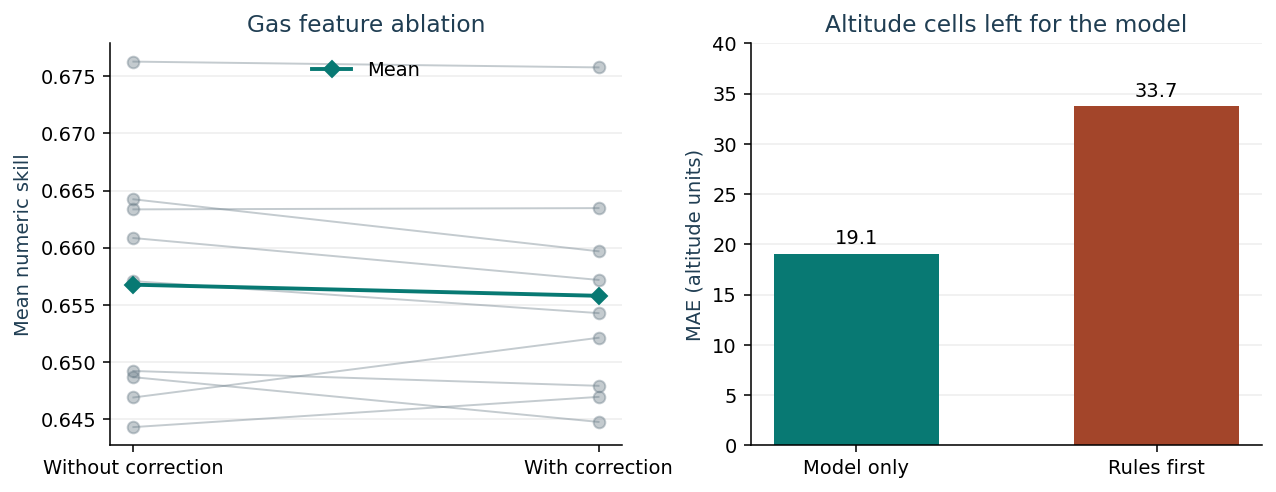

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
cols = ["Without correction", "With correction"]
for _, values in features[cols].iterrows():
    axes[0].plot(cols, values, marker="o", color=MUTE, alpha=0.38, linewidth=1)
axes[0].plot(cols, features[cols].mean(), marker="D", color=TEAL, linewidth=2, label="Mean")
axes[0].set(title="Gas feature ablation", ylabel="Mean numeric skill")
axes[0].legend(frameon=False)
axes[0].grid(axis="y")

bars = axes[1].bar(residual_table.index, residual_table.iloc[:, 0], color=[TEAL, RUST], width=0.55)
axes[1].bar_label(bars, fmt="%.1f", padding=3)
axes[1].set(title="Altitude cells left for the model", ylabel="MAE (altitude units)", ylim=(0, 40))
axes[1].grid(axis="y")
plt.show()

## Interpretation

Both arms round to 0.656 mean numeric skill with the gas features enabled. The direct rule contribution of about +0.022 is almost offset by the remaining gaps at −0.021. Altitude illustrates the trade-off. The rule fills 2,645 altitude gaps exactly and raises the share within loose tolerance. On the 2,813 residual altitude gaps, MAE rises from 19.1 to 33.7.

The saved row audit found **0** residual altitude test rows with a raw input changed by the rules. That rules out a direct test-row input edit on this subset. The fitted pipeline differs across arms, and the specific cause of the residual error increase remains unresolved.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/macro_run_scores.csv | Matched MissForest anchor scores for both feature settings and arms | 280b4303444c8d02 |
| final/tables/rule_effects.csv | Paired geometry and remaining-gap error decomposition | 811032c8cc7acbc3 |
| final/tables/cells.csv | Altitude skill and loose tolerance by pair and arm | 9d8119486d0cbae0 |
| final-review/checks.json | Archived check of raw test inputs on residual altitude rows | ee55237661f62f89 |

[Sections 6 and 10 of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)